In [16]:
!python -m pytest test_digital.py -v

============================= test session starts =============================
platform win32 -- Python 3.13.14, pytest-8.4.2, pluggy-1.7.0 -- C:\Users\tolya\PycharmProjects\QuantCourseBP\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\tolya\PycharmProjects\QuantCourseBP\homeworks\51029fc\hw3\solution
plugins: anyio-4.15.1, platformdirs-4.13.0
collecting ... collected 48 items

test_digital.py::test_digital_fair_value[CALL-0.5-0.5-BLUECHIP_BANK] PASSED [  2%]
test_digital.py::test_digital_fair_value[CALL-0.5-0.5-TIPTOP_SOLUTIONS] PASSED [  4%]
test_digital.py::test_digital_fair_value[CALL-0.5-1.0-BLUECHIP_BANK] PASSED [  6%]
test_digital.py::test_digital_fair_value[CALL-0.5-1.0-TIPTOP_SOLUTIONS] PASSED [  8%]
test_digital.py::test_digital_fair_value[CALL-0.5-1.5-BLUECHIP_BANK] PASSED [ 10%]
test_digital.py::test_digital_fair_value[CALL-0.5-1.5-TIPTOP_SOLUTIONS] PASSED [ 12%]
test_digital.py::test_digital_fair_value[CALL-1.0-0.5-BLUECHIP_BANK] PASSED [ 14%]
test_digi

## All tests are passed

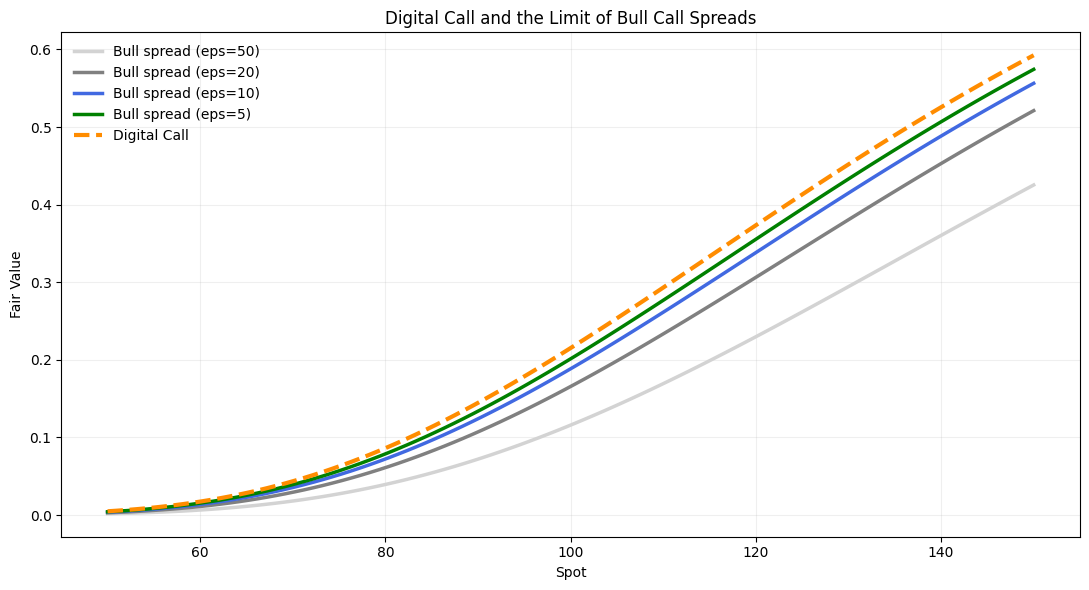

In [50]:
from scipy.stats import norm

S = np.linspace(50, 150, 100)
T = 1.0
r = model.risk_free_rate
eps = [50, 20, 10, 5, 0.5]
vol = model.vol

def call_price(S, K):
    d1 = (np.log(S / K) + (r + vol**2 / 2) * T) / (vol * np.sqrt(T))
    d2 = d1 - vol * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def digital_price(S, K):
    d2 = (np.log(S / K) + (r - vol**2 / 2) * T) / (vol * np.sqrt(T))
    return np.exp(-r * T) * norm.cdf(d2)

fig, ax = plt.subplots(figsize=(11, 6))

for eps, color in zip(eps, colors):
    fair_value = (
        call_price(S, K) - call_price(S, K + eps)
    ) / eps

    ax.plot(
        S, fair_value,
        color=color,
        linewidth=2.5,
        label=f'Bull spread (eps={eps})'
    )

ax.plot(
    S, digital_price(S, K),
    color='darkorange',
    linewidth=3,
    linestyle='--',
    label='Digital Call'
)

ax.set_title('Digital Call and the Limit of Bull Call Spreads')
ax.set_xlabel('Spot')
ax.set_ylabel('Fair Value')
ax.grid(alpha=0.2)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

digital call pays 1 if stock > strike, 0 otherwise =>

payoff has rapid jump at S = K

bull spread:

long call K - eps
short call K + eps

if we take lim eps -> 0, we get digital call option

it's visible on the graph above: smaller eps, closer to digital case